In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# Load dataset
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

# Make a copy of original data
original_df = df.copy()

print("Dataset Name: Titanic Passenger Dataset")
print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
print(df.head())

print("\nLast 5 Rows:")
print(df.tail())

Dataset Name: Titanic Passenger Dataset
Dataset Shape: (891, 12)

First 5 Rows:
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  

In [ ]:
print("Column Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

# Separate numerical and categorical columns
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()

print("\nNumerical Columns:")
print(numerical_cols)

print("\nCategorical Columns:")
print(categorical_cols)

print("\nSummary Statistics:")
print(df.describe())

Column Names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Data Types:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       8

In [ ]:
missing_count = df.isnull().sum()
missing_percentage = (missing_count / len(df)) * 100

missing_report = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage": missing_percentage.round(2)
})

print(missing_report)

             Missing Values  Missing Percentage
PassengerId               0                0.00
Survived                  0                0.00
Pclass                    0                0.00
Name                      0                0.00
Sex                       0                0.00
Age                     177               19.87
SibSp                     0                0.00
Parch                     0                0.00
Ticket                    0                0.00
Fare                      0                0.00
Cabin                   687               77.10
Embarked                  2                0.22


In [ ]:
# Create a separate copy for cleaning
clean_df = original_df.copy()

# Fill missing Age values using median
clean_df["Age"] = clean_df["Age"].fillna(
    clean_df["Age"].median()
)

# Fill missing Embarked values using mode
clean_df["Embarked"] = clean_df["Embarked"].fillna(
    clean_df["Embarked"].mode()[0]
)

# Drop Cabin because it has a very high percentage of missing values
clean_df = clean_df.drop(columns=["Cabin"])

# Remove extra spaces from categorical text
for col in ["Name", "Sex", "Ticket", "Embarked"]:
    clean_df[col] = clean_df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

# Check and remove exact duplicate rows
print("Duplicates before cleaning:", clean_df.duplicated().sum())
clean_df = clean_df.drop_duplicates()

print("\nMissing Values After Cleaning:")
print(clean_df.isnull().sum())

print("\nShape After Cleaning:", clean_df.shape)

Duplicates before cleaning: 0

Missing Values After Cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

Shape After Cleaning: (891, 11)


Numerical Summary:
       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  891.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.361582    0.523008   
std     257.353842    0.486592    0.836071   13.019697    1.102743   
min       1.000000    0.000000    1.000000    0.420000    0.000000   
25%     223.500000    0.000000    2.000000   22.000000    0.000000   
50%     446.000000    0.000000    3.000000   28.000000    0.000000   
75%     668.500000    1.000000    3.000000   35.000000    1.000000   
max     891.000000    1.000000    3.000000   80.000000    8.000000   

            Parch        Fare  
count  891.000000  891.000000  
mean     0.381594   32.204208  
std      0.806057   49.693429  
min      0.000000    0.000000  
25%      0.000000    7.910400  
50%      0.000000   14.454200  
75%      0.000000   31.000000  
max      6.000000  512.329200  

Passenger Gender Counts:
Sex
male      577
female    314
Name

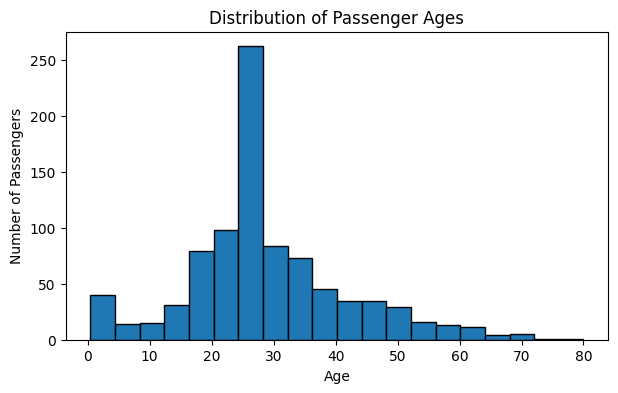

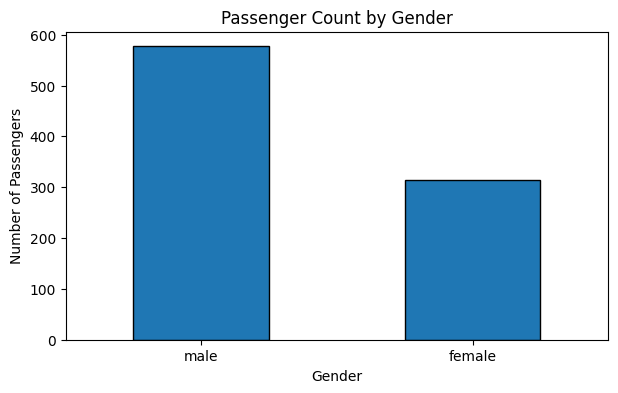

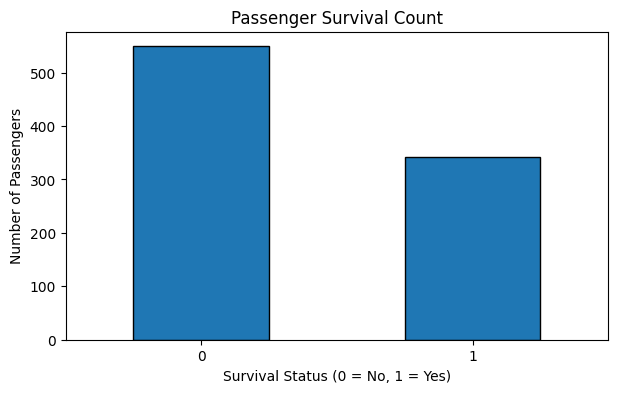

In [ ]:
# Numerical summary
print("Numerical Summary:")
print(clean_df.describe())

# Frequency count of categorical data
print("\nPassenger Gender Counts:")
print(clean_df["Sex"].value_counts())

# Visualization 1: Age distribution
plt.figure(figsize=(7, 4))
plt.hist(clean_df["Age"], bins=20, edgecolor="black")
plt.title("Distribution of Passenger Ages")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.show()

# Visualization 2: Passenger count by gender
clean_df["Sex"].value_counts().plot(
    kind="bar", figsize=(7, 4), edgecolor="black"
)
plt.title("Passenger Count by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=0)
plt.show()

# Visualization 3: Survival count
clean_df["Survived"].value_counts().sort_index().plot(
    kind="bar", figsize=(7, 4), edgecolor="black"
)
plt.title("Passenger Survival Count")
plt.xlabel("Survival Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=0)
plt.show()

In [ ]:
# Remove identifier and descriptive text columns not required
# for this basic machine-learning preparation exercise
prepared_df = clean_df.drop(
    columns=["PassengerId", "Name", "Ticket"]
)

# One-hot encode nominal categorical columns
prepared_df = pd.get_dummies(
    prepared_df,
    columns=["Sex", "Embarked"],
    dtype=int
)

print("Dataset After Encoding:")
print(prepared_df.head())

print("\nShape After Encoding:", prepared_df.shape)

Dataset After Encoding:
   Survived  Pclass   Age  SibSp  Parch     Fare  Sex_female  Sex_male  \
0         0       3  22.0      1      0   7.2500           0         1   
1         1       1  38.0      1      0  71.2833           1         0   
2         1       3  26.0      0      0   7.9250           1         0   
3         1       1  35.0      1      0  53.1000           1         0   
4         0       3  35.0      0      0   8.0500           0         1   

   Embarked_C  Embarked_Q  Embarked_S  
0           0           0           1  
1           1           0           0  
2           0           0           1  
3           0           0           1  
4           0           0           1  

Shape After Encoding: (891, 11)


In [ ]:
# Scale input features only, not the target column Survived
scale_cols = ["Age", "Fare", "SibSp", "Parch"]

scaler = StandardScaler()
prepared_df[scale_cols] = scaler.fit_transform(
    prepared_df[scale_cols]
)

print("Dataset After Scaling:")
print(prepared_df.head())

print("\nScaled Feature Means:")
print(prepared_df[scale_cols].mean().round(2))

Dataset After Scaling:
   Survived  Pclass       Age     SibSp     Parch      Fare  Sex_female  \
0         0       3 -0.565736  0.432793 -0.473674 -0.502445           0   
1         1       1  0.663861  0.432793 -0.473674  0.786845           1   
2         1       3 -0.258337 -0.474545 -0.473674 -0.488854           1   
3         1       1  0.433312  0.432793 -0.473674  0.420730           1   
4         0       3  0.433312 -0.474545 -0.473674 -0.486337           0   

   Sex_male  Embarked_C  Embarked_Q  Embarked_S  
0         1           0           0           1  
1         0           1           0           0  
2         0           0           0           1  
3         0           0           0           1  
4         1           0           0           1  

Scaled Feature Means:
Age      0.0
Fare     0.0
SibSp    0.0
Parch    0.0
dtype: float64


In [ ]:
# Final verification
print("Final Dataset Shape:", prepared_df.shape)

print("\nRemaining Missing Values:",
      prepared_df.isnull().sum().sum())

print("Remaining Duplicate Rows:",
      prepared_df.duplicated().sum())

print("\nFinal Prepared Dataset Sample:")
print(prepared_df.head())

# Save as a separate CSV file
prepared_df.to_csv("prepared_titanic.csv", index=False)

print("\nDataset saved successfully as prepared_titanic.csv")

Final Dataset Shape: (891, 11)

Remaining Missing Values: 0
Remaining Duplicate Rows: 116

Final Prepared Dataset Sample:
   Survived  Pclass       Age     SibSp     Parch      Fare  Sex_female  \
0         0       3 -0.565736  0.432793 -0.473674 -0.502445           0   
1         1       1  0.663861  0.432793 -0.473674  0.786845           1   
2         1       3 -0.258337 -0.474545 -0.473674 -0.488854           1   
3         1       1  0.433312  0.432793 -0.473674  0.420730           1   
4         0       3  0.433312 -0.474545 -0.473674 -0.486337           0   

   Sex_male  Embarked_C  Embarked_Q  Embarked_S  
0         1           0           0           1  
1         0           1           0           0  
2         0           0           0           1  
3         0           0           0           1  
4         1           0           0           1  

Dataset saved successfully as prepared_titanic.csv


In [ ]:
# Check duplicates in the original cleaned dataset
print("Duplicates before feature removal:",
      clean_df.duplicated().sum())

# Remove duplicate rows from the prepared dataset
prepared_df = prepared_df.drop_duplicates().reset_index(drop=True)

# Verify final dataset
print("\nFinal Dataset Shape:", prepared_df.shape)
print("Remaining Missing Values:",
      prepared_df.isnull().sum().sum())
print("Remaining Duplicate Rows:",
      prepared_df.duplicated().sum())

# Save final dataset
prepared_df.to_csv("prepared_titanic.csv", index=False)

print("\nDataset saved successfully as prepared_titanic.csv")

Duplicates before feature removal: 0

Final Dataset Shape: (775, 11)
Remaining Missing Values: 0
Remaining Duplicate Rows: 0

Dataset saved successfully as prepared_titanic.csv


In [ ]:
# Recreate prepared dataset from cleaned data
prepared_df = clean_df.drop(
    columns=["PassengerId", "Name", "Ticket"]
)

# Encode categorical columns
prepared_df = pd.get_dummies(
    prepared_df,
    columns=["Sex", "Embarked"],
    dtype=int
)

# Scale numerical features
scale_cols = ["Age", "Fare", "SibSp", "Parch"]
scaler = StandardScaler()
prepared_df[scale_cols] = scaler.fit_transform(
    prepared_df[scale_cols]
)

# Verify dataset
print("Final Dataset Shape:", prepared_df.shape)
print("Missing Values:", prepared_df.isnull().sum().sum())
print("Duplicate Rows:", prepared_df.duplicated().sum())

# Save dataset
prepared_df.to_csv("prepared_titanic.csv", index=False)
print("Dataset saved successfully!")

Final Dataset Shape: (891, 11)
Missing Values: 0
Duplicate Rows: 116
Dataset saved successfully!


In [ ]:
print("Original Cleaned Dataset Shape:", clean_df.shape)
print("Missing Values:", clean_df.isnull().sum().sum())
print("Duplicate Passenger Records:", clean_df.duplicated().sum())

Original Cleaned Dataset Shape: (891, 11)
Missing Values: 0
Duplicate Passenger Records: 0


In [ ]:
from google.colab import files
files.download("prepared_titanic.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Conclusion:**

In this activity, I used the Titanic Passenger Dataset to perform data preparation and exploratory data analysis using Python. I inspected the dataset structure, column names, data types, and summary statistics. Missing values in the Age and Embarked columns were handled using median and mode imputation, respectively. The Cabin column was removed because it contained a high percentage of missing values. Duplicate records were checked, categorical features were encoded using one-hot encoding, and selected numerical features were standardized using StandardScaler. Histograms and bar charts were created to understand the data distribution. Finally, the prepared dataset was saved as `prepared_titanic.csv`. This activity helped me understand the importance of data cleaning and preprocessing before machine learning.